## Exploratory data analysis 

- **Part-1: Data overview**
    > check the #samples, #attributes <br>
    > attribute types <br>
    
- **Part-2: Data cleaning**
    > organize attributes into appripriate data types (e.g., numerical, categorical) <br>
    > missing value and outlier detection <br>
    
- **Part-3: Data transformation**
    > explore target variable <br>
    > normalize numerical data <br>
    
- **Part-4: Feature engineering**
    > encode categorical data <br>

- **Part-5: Additional analysis**
    > colinearty check <br>


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

### Data overview

In [3]:
# read data from file to a pandas dataframe
df = pd.read_csv('./customer_data.csv') 

In [4]:
# check the shape of the data frame: row: #samples, column: #attributes 
df.shape

(100000, 12)

We can see that there are 100000 samples and 12 attributes.

In [5]:
# get an overview of the top 20 rows/samples
df.head(20)

,id,age,gender,income,education,region,loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score
0,1,27,Male,40682,Bachelor,East,Gold,frequent,18249,Books,0,6
1,2,29,Male,15317,Masters,West,Regular,rare,4557,Clothing,1,6
2,3,37,Male,38849,Bachelor,West,Silver,rare,11822,Clothing,0,6
3,4,30,Male,11568,HighSchool,South,Regular,frequent,4098,Food,0,7
4,5,31,Female,46952,College,North,Regular,occasional,19685,Clothing,1,5
5,6,38,Male,7347,Bachelor,South,Silver,occasional,2822,Electronics,0,5
6,7,32,Female,8265,Bachelor,South,Silver,frequent,3293,Clothing,0,7
7,8,24,Female,47773,HighSchool,North,Regular,rare,21794,Books,0,5
8,9,27,Male,19154,College,East,Regular,occasional,5819,Clothing,0,5
9,10,28,Female,24666,HighSchool,North,Regular,rare,8779,Food,0,6


### Data cleaning

In [6]:
# Check if there is any missing value
null_sum = df.isnull().sum()
null_sum

id                    0
age                   0
gender                0
income                0
education             0
region                0
loyalty_status        0
purchase_frequency    0
purchase_amount       0
product_category      0
promotion_usage       0
satisfaction_score    0
dtype: int64

In [7]:
# Check the data types
df.dtypes 

id                     int64
age                    int64
gender                object
income                 int64
education             object
region                object
loyalty_status        object
purchase_frequency    object
purchase_amount        int64
product_category      object
promotion_usage        int64
satisfaction_score     int64
dtype: object

#### organize columns into different data types
The .dtype attribute shows that the current data type for numerical data is "int", and data type for numerical data is "object".   

We will organize the columns into the following common data types based on the observation (decide the data type based on its values):
- Categorical: 
    > id, gender,region, loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score <br>
- Numerical: 
    > income,purchase_amount <br>

In the following part, we will: 
- convert the original data into the organized data type 
- do data processing for the converted data

#### process categorical data

In [8]:
# Convert the following columns to categorical data types 
cat_col = ['id', 'gender', 'education', 'region', 'loyalty_status', 'product_category', 'promotion_usage', 'purchase_frequency']
df[cat_col] = df[cat_col].astype('category')
df[cat_col]

,id,gender,education,region,loyalty_status,product_category,promotion_usage,purchase_frequency
0,1,Male,Bachelor,East,Gold,Books,0,frequent
1,2,Male,Masters,West,Regular,Clothing,1,rare
2,3,Male,Bachelor,West,Silver,Clothing,0,rare
3,4,Male,HighSchool,South,Regular,Food,0,frequent
4,5,Female,College,North,Regular,Clothing,1,occasional
...,...,...,...,...,...,...,...,...
99995,99996,Female,College,West,Regular,Health,0,occasional
99996,99997,Male,HighSchool,South,Regular,Health,0,rare
99997,99998,Male,College,West,Regular,Clothing,0,frequent
99998,99999,Female,Bachelor,West,Regular,Health,1,frequent


In [9]:
# the category columns now all have the categorical data types
df[cat_col].dtypes

id                    category
gender                category
education             category
region                category
loyalty_status        category
product_category      category
promotion_usage       category
purchase_frequency    category
dtype: object

**check outliers of each categorical feature**

In [10]:
df['gender'].value_counts() 

gender
Female    50074
Male      49926
Name: count, dtype: int64

In [11]:
df['education'].value_counts() 

education
College       39874
Bachelor      30279
HighSchool    20031
Masters        9816
Name: count, dtype: int64

In [12]:
df['region'].value_counts() 

region
East     30074
West     29935
South    20073
North    19918
Name: count, dtype: int64

In [13]:
df['loyalty_status'].value_counts() 

loyalty_status
Regular    60138
Silver     29964
Gold        9898
Name: count, dtype: int64

In [14]:
df['product_category'].value_counts() 

product_category
Electronics    30027
Clothing       19989
Books          14925
Food           14822
Health         10123
Home            5079
Beauty          5035
Name: count, dtype: int64

In [15]:
df['promotion_usage'].value_counts() 

promotion_usage
0    69920
1    30080
Name: count, dtype: int64

In [16]:
df['purchase_frequency'].value_counts() 

purchase_frequency
rare          50019
occasional    29886
frequent      20095
Name: count, dtype: int64

We can see that for categorical data, there is no obvious outliners to be dropped. Also, they're basically reasonably distributed. For this moment, we're considering further encode the categorical data based on their current categories. But for loyalty_status and purchase_frequency, we may consider convert them into binary variables.

#### process numerical data

In [17]:
#create numerical columns
num_col = ['income','purchase_amount']

In [18]:
# for future transformation,float
df[num_col] = df[num_col].astype('float')
df[num_col].dtypes

income             float64
purchase_amount    float64
dtype: object

In [19]:
# descriptive statistics for the numerical columns
df[num_col].describe()

,income,purchase_amount
count,100000.000000,100000.000000
mean,27516.269880,9634.790840
std,12996.782587,4799.339449
min,5000.000000,1118.000000
25%,16271.750000,5583.000000
50%,27584.500000,9452.000000
75%,38747.250000,13350.000000
max,50000.000000,26204.000000


##### for 'income'

<Axes: xlabel='income'>

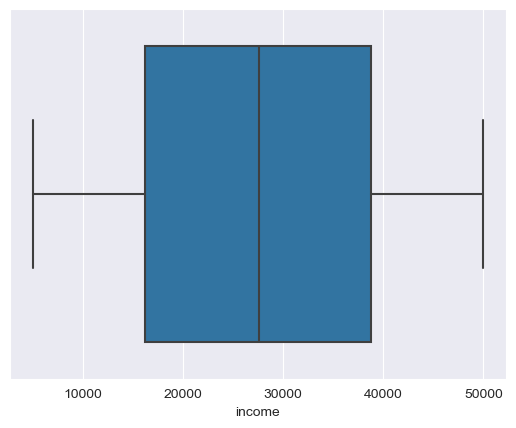

In [20]:
# draw box plot to check outliers
sns.set_style("darkgrid",{'axes.grid' : True})
sns.boxplot(x=df['income'], orient='h')

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='income', ylabel='Count'>

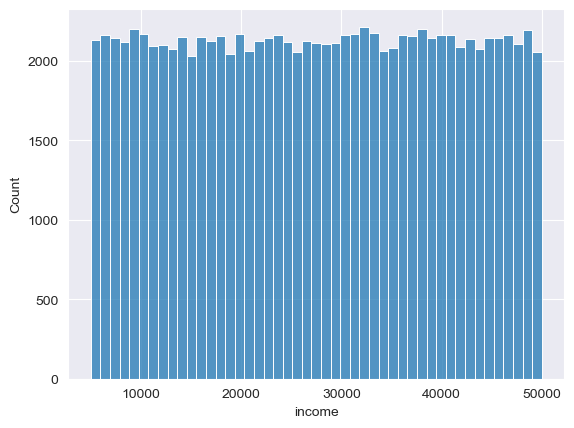

In [21]:
sns.histplot(df['income'])

In [22]:
Q1 = df['income'].quantile(0.25)
Q3 = df['income'].quantile(0.75)
IQR = Q3 - Q1
lower_thresh = Q1 - 1.5*IQR
upper_thresh = Q3 + 1.5*IQR
Q1, Q3, lower_thresh, upper_thresh

(16271.75, 38747.25, -17441.5, 72460.5)

##### for 'purchase_amount'

<Axes: xlabel='purchase_amount'>

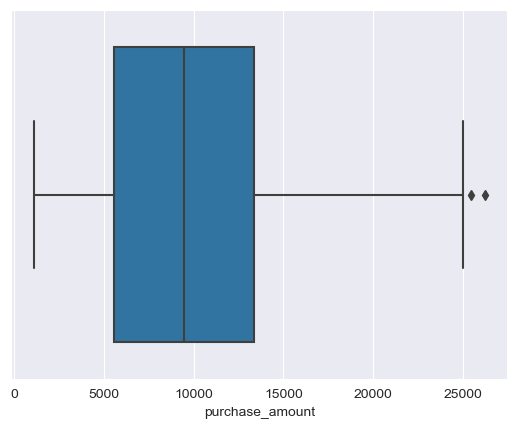

In [23]:
# draw box plot to check outliers
sns.set_style("darkgrid",{'axes.grid' : True})
sns.boxplot(x=df['purchase_amount'], orient='h')

In [24]:
Q1 = df['purchase_amount'].quantile(0.25)
Q3 = df['purchase_amount'].quantile(0.75)
IQR = Q3 - Q1
lower_thresh = Q1 - 1.5*IQR
upper_thresh = Q3 + 1.5*IQR
Q1, Q3, lower_thresh, upper_thresh

(5583.0, 13350.0, -6067.5, 25000.5)

In [25]:
df['purchase_amount'].min( )
df['purchase_amount'].max( )

26204.0

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

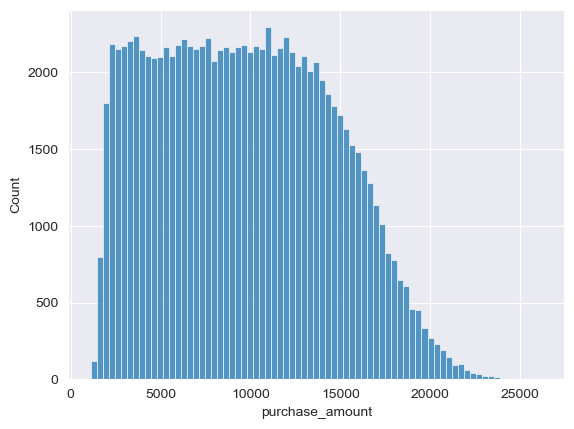

In [26]:
sns.histplot(df['purchase_amount'])

In [27]:
# Based on the above calculation, we will remove samples that have "purchase_amount" above 21000 (>21000) as outliers 
# since they‘re extremely high
df.drop(df[df['purchase_amount'] > 21000].index, inplace=True)
df.shape

(99523, 12)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

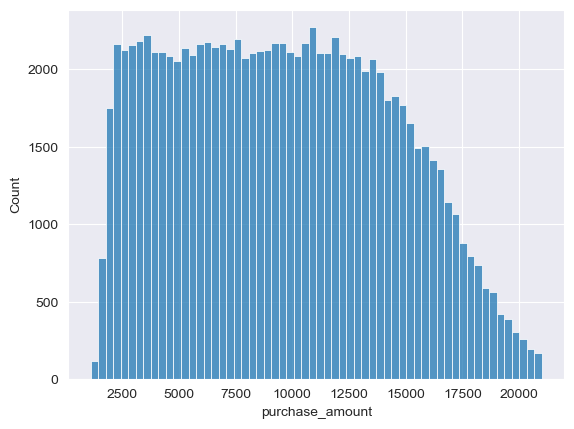

In [28]:
# check the current distribution
sns.histplot(df['purchase_amount'])

### Data transformation
In this part, we will move forward to do data transformation mainly for target variable and numerical data.

#### Transform Target Variable

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='satisfaction_score', ylabel='Count'>

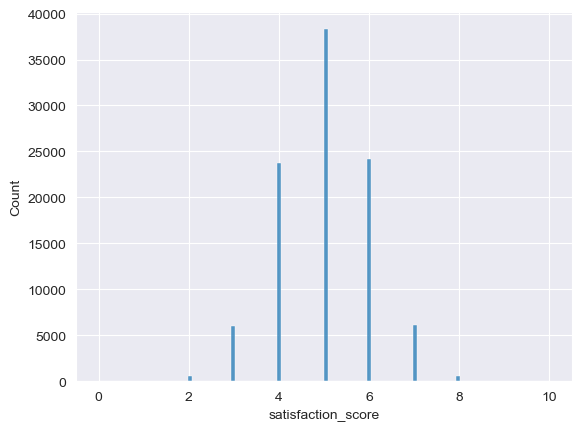

In [29]:
sns.histplot(df['satisfaction_score'])

In [30]:
# We took 5 as a thershold, when satisfaction_score>5, it's considered as satisfied, when <5 it's considered as unsatisfied
conditions = [df['satisfaction_score'] < 5, df['satisfaction_score'] >= 5]
values = ['unsatisfied', 'satisfied']

# Use numpy.where() to set values based on conditions
df['satisfaction_category'] = np.where(conditions[0], values[0], np.where(conditions[1], values[1], np.nan))
df['satisfaction_category'].head(30)

0       satisfied
1       satisfied
2       satisfied
3       satisfied
4       satisfied
5       satisfied
6       satisfied
8       satisfied
9       satisfied
10      satisfied
11      satisfied
12      satisfied
13      satisfied
14    unsatisfied
15      satisfied
17    unsatisfied
18      satisfied
19      satisfied
20      satisfied
21      satisfied
22      satisfied
23    unsatisfied
24      satisfied
25      satisfied
26      satisfied
27      satisfied
28      satisfied
29    unsatisfied
30      satisfied
31    unsatisfied
Name: satisfaction_category, dtype: object

#### Normalize numerical data

#####  Normalize “income”

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='income', ylabel='Count'>

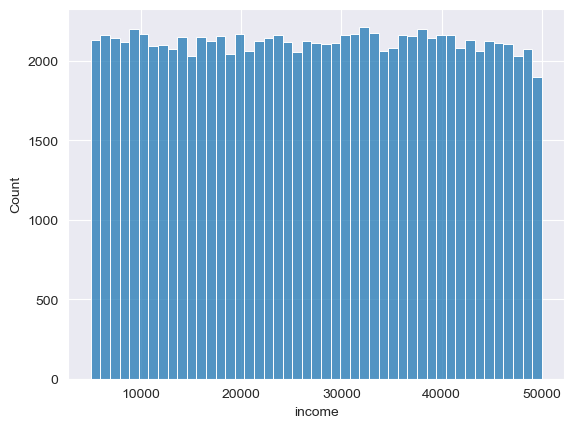

In [31]:
# check the distribution of the "income" before normalization
sns.histplot(df['income'])

In [32]:
# normalize income
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
df['income'] = scaler.fit_transform(df[['income']].values)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='income', ylabel='Count'>

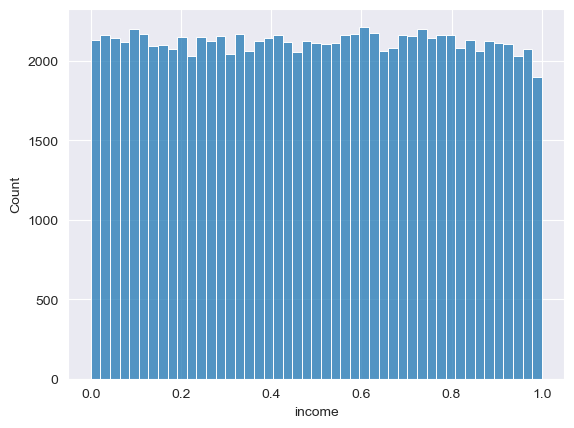

In [33]:
# check the distribution of the "income" after normalization
sns.histplot(df['income'] )

##### Normalize “purchase_amount”

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

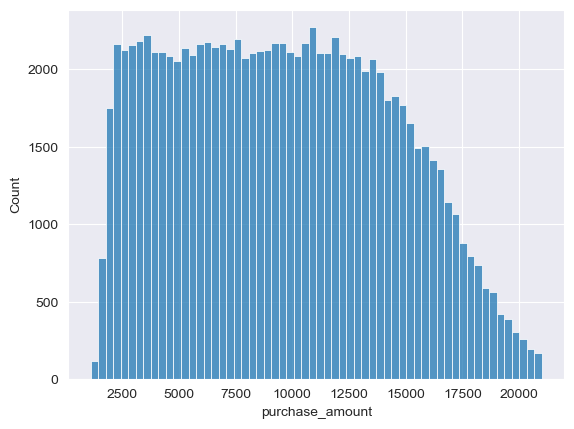

In [34]:
# check the distribution of the "purchase_amount" before normalization
sns.histplot(df['purchase_amount'])

In [35]:
# normalize income
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
df['purchase_amount'] = scaler.fit_transform(df[['purchase_amount']].values)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

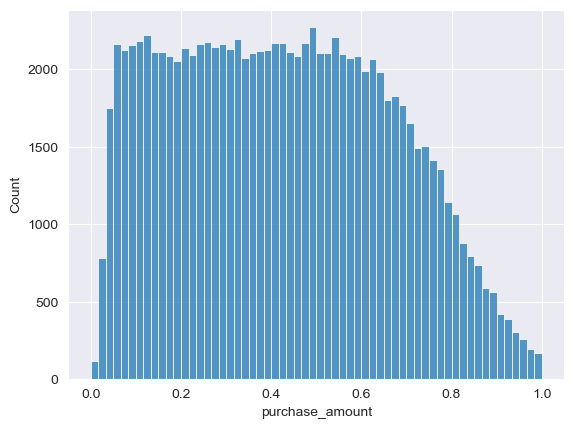

In [36]:
# check the distribution of the "purchase amount" after normalization
sns.histplot(df['purchase_amount'] )

We can see that normalization doesn't change the distribution.

### Feature Engineering

#### Numerical data
- directly use the values

#### Categorical data
- encoding (one-hot/ordinal encoder)

In [37]:
from sklearn.preprocessing import OneHotEncoder

In [38]:
df.head()

,id,age,gender,income,education,region,loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score,satisfaction_category
0,1,27,Male,0.792933,Bachelor,East,Gold,frequent,0.861764,Books,0,6,satisfied
1,2,29,Male,0.229267,Masters,West,Regular,rare,0.172997,Clothing,1,6,satisfied
2,3,37,Male,0.752200,Bachelor,West,Silver,rare,0.538458,Clothing,0,6,satisfied
3,4,30,Male,0.145956,HighSchool,South,Regular,frequent,0.149907,Food,0,7,satisfied
4,5,31,Female,0.932267,College,North,Regular,occasional,0.934001,Clothing,1,5,satisfied


In [39]:
# Initiate one-hot encoder
ohe = OneHotEncoder(handle_unknown='ignore')
ohe_col = ['gender', 'education', 'region', 'loyalty_status', 'product_category', 'promotion_usage', 'purchase_frequency']
ohe.fit(df[ohe_col]) 

# encode the features with the learned categories during the fit process
ohe_features = pd.DataFrame(ohe.transform(df[ohe_col]).toarray())
print(ohe_features)


        0    1    2    3    4    5    6    7    8    9   ...   15   16   17  \
0      0.0  1.0  1.0  0.0  0.0  0.0  1.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
1      0.0  1.0  0.0  0.0  0.0  1.0  0.0  0.0  0.0  1.0  ...  1.0  0.0  0.0   
2      0.0  1.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  1.0  0.0  0.0   
3      0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0  1.0  0.0  ...  0.0  0.0  1.0   
4      1.0  0.0  0.0  1.0  0.0  0.0  0.0  1.0  0.0  0.0  ...  1.0  0.0  0.0   
...    ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...   
99518  1.0  0.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  0.0  0.0  0.0   
99519  0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0  1.0  0.0  ...  0.0  0.0  0.0   
99520  0.0  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  1.0  0.0  0.0   
99521  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  0.0  0.0  0.0   
99522  1.0  0.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  0.0  0.0  0.0   

        18   19   20   21   22   23   24  
0      0

In [40]:
# rename columns so we can analyze them later
col_names = []
for i in range(len(ohe_col)):
    for j in ohe.categories_[i]:
        col_names.append(ohe_col[i] + '_' + str(j))

names_dict = {i:col_names[i] for i in range(len(col_names))}
ohe_features.rename(columns=names_dict, inplace=True)
ohe_features

,gender_Female,gender_Male,education_Bachelor,education_College,education_HighSchool,education_Masters,region_East,region_North,region_South,region_West,...,product_category_Clothing,product_category_Electronics,product_category_Food,product_category_Health,product_category_Home,promotion_usage_0,promotion_usage_1,purchase_frequency_frequent,purchase_frequency_occasional,purchase_frequency_rare
0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99518,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
99519,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
99520,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
99521,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0


### Additional Analysis

#### Check the colinearity

Text(0.5, 1.0, 'Correlation Heatmap')

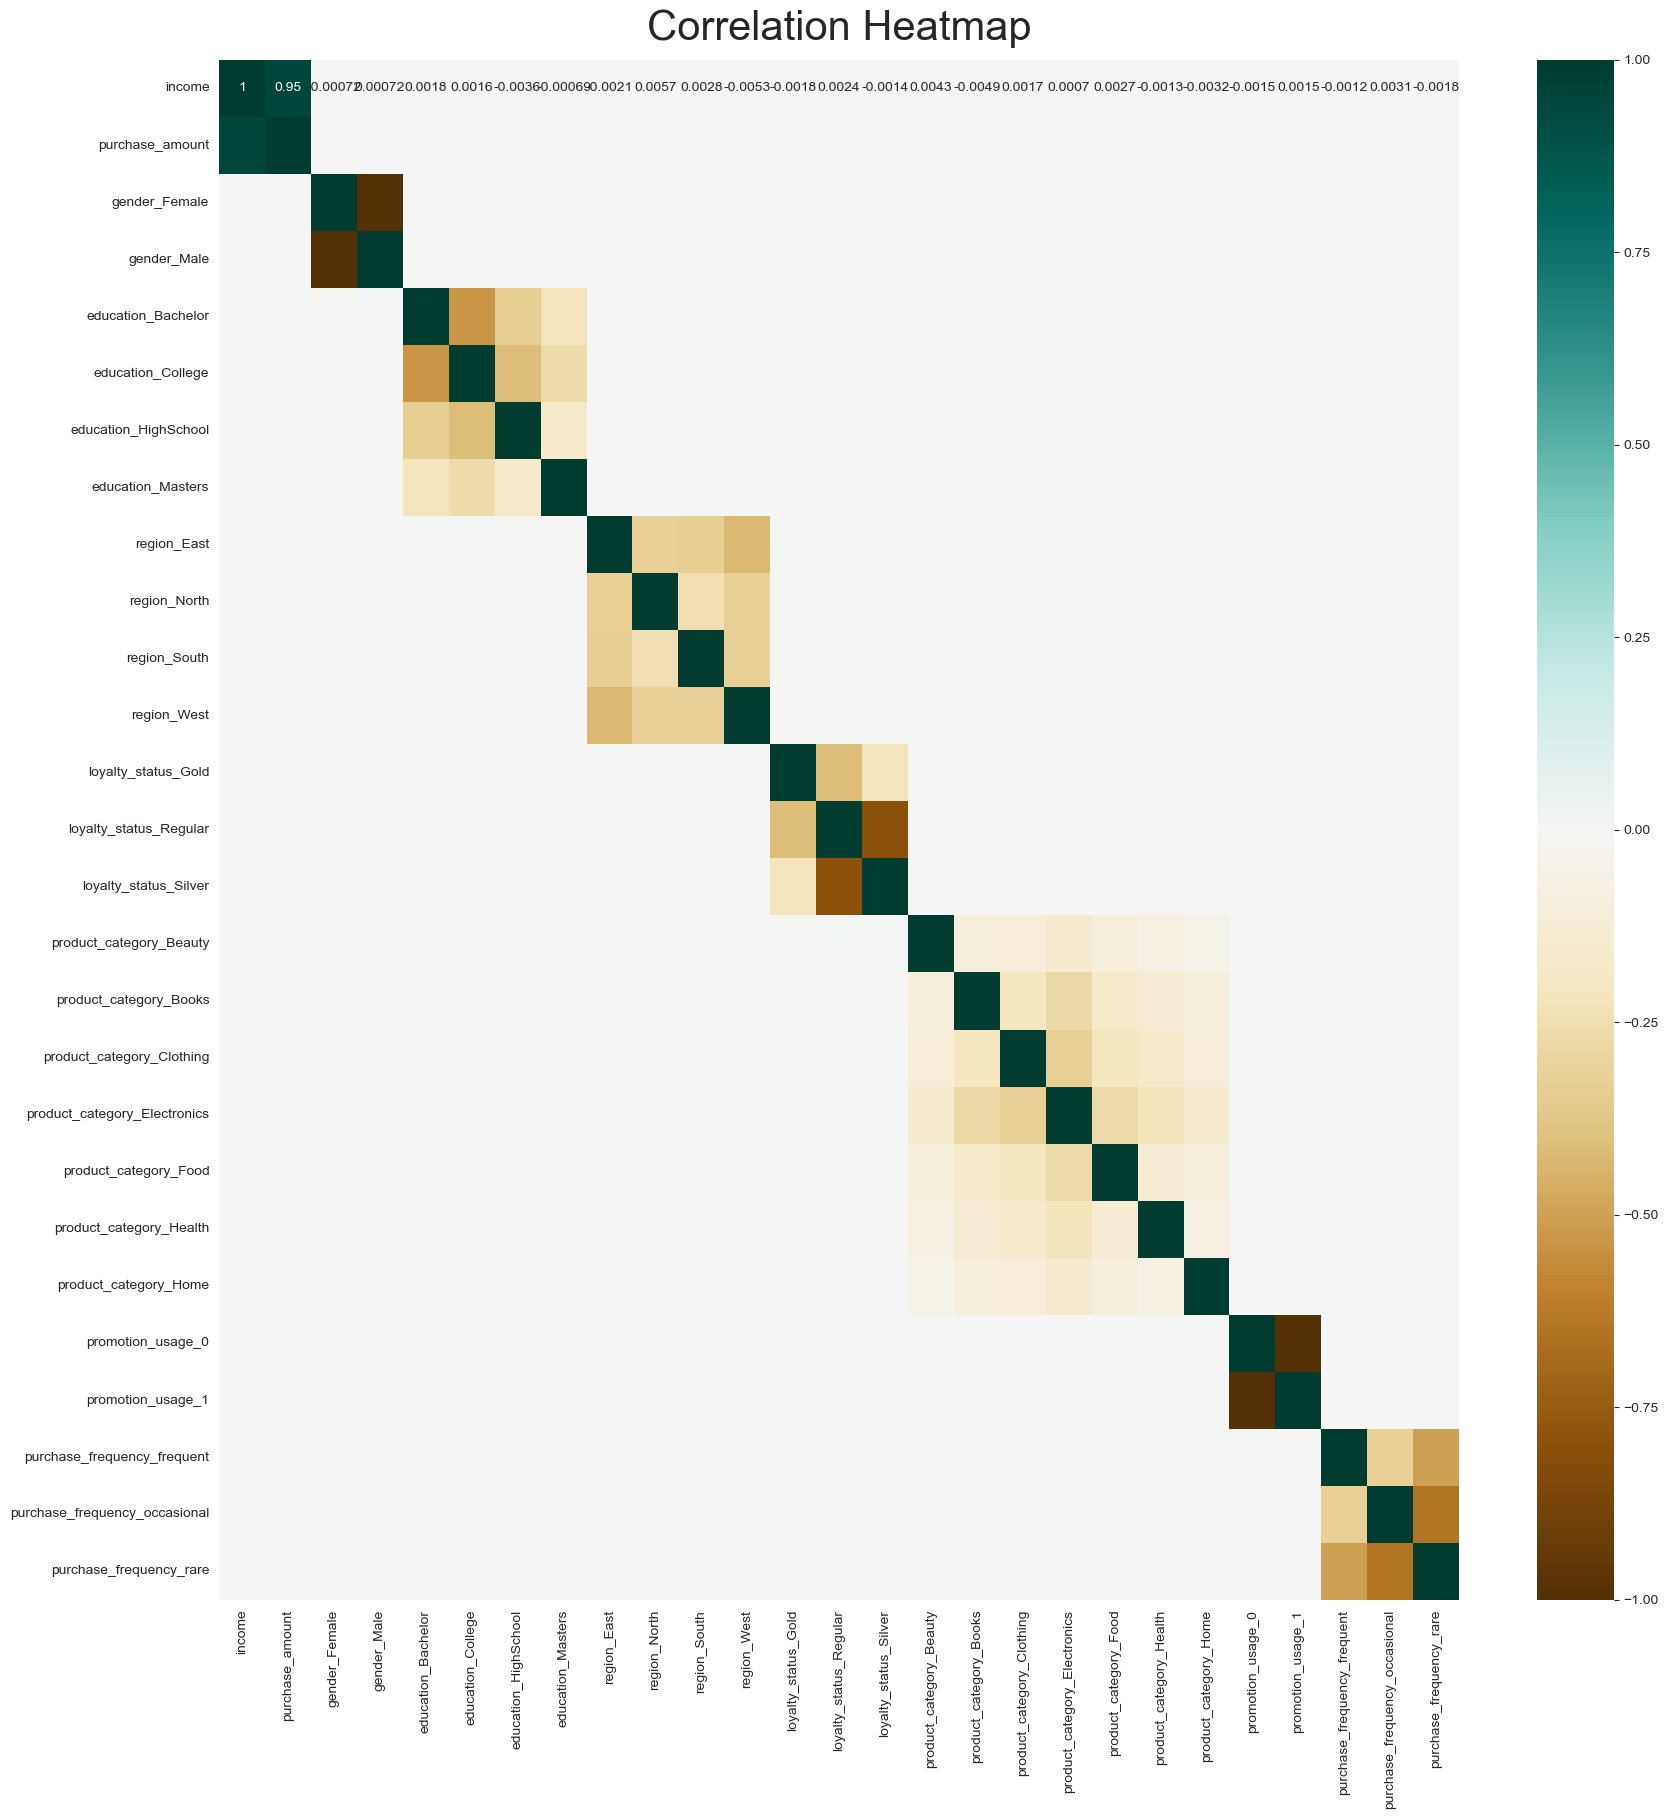

In [41]:
# set the size of the heatmap.
plt.figure(figsize=(20, 20))

#Create the heatmap using Seaborn and adjust the font size of annotations

df.reset_index(drop=True, inplace=True)
ohe_features.reset_index(drop=True, inplace=True)

# Concatenate the DataFrames
df_X = pd.concat([df[['income', 'purchase_amount']], ohe_features], axis=1)
heatmap = sns.heatmap(df_X.corr(), vmin=-1, vmax=1, cmap='BrBG',annot=True)

#Set the title
heatmap.set_title('Correlation Heatmap', fontdict={'fontsize':30}, pad=14)

## Supervised Learning

In this part, we're going to apply supervised learning models to the dataset. We want to conduct a classfication task to see if and how the features explain the customer's satisfaction.
We would use tree-based models in this part, mainly decision-tree classifier. It's suitable for a binary classification task and it's easy to understand.

### Create train-test split

In [42]:
# Create feature matrix X by concatenating numeric and OHE feature matrix

# Reset indices of df and ohe_features
df.reset_index(drop=True, inplace=True)
ohe_features.reset_index(drop=True, inplace=True)

# Concatenate the DataFrames
df_X = pd.concat([df[['income', 'purchase_amount']], ohe_features], axis=1)

df_X .head(10)

,income,purchase_amount,gender_Female,gender_Male,education_Bachelor,education_College,education_HighSchool,education_Masters,region_East,region_North,...,product_category_Clothing,product_category_Electronics,product_category_Food,product_category_Health,product_category_Home,promotion_usage_0,promotion_usage_1,purchase_frequency_frequent,purchase_frequency_occasional,purchase_frequency_rare
0,0.792933,0.861764,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,0.229267,0.172997,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,0.752200,0.538458,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.145956,0.149907,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,0.932267,0.934001,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
5,0.052156,0.085719,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
6,0.072556,0.109412,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
7,0.314533,0.236481,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
8,0.437022,0.385382,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
9,0.864356,0.756577,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


In [43]:
df_X.shape

(99523, 27)

In [44]:
# Create target variable
target = 'satisfaction_category'
df_y = df[[target]]
df_y.head(10)
df_y.shape

(99523, 1)

In [45]:
from sklearn.model_selection import train_test_split

# Create split with Sklearn
df_X_train, df_X_test, df_y_train, df_y_test  = train_test_split(df_X, df_y, test_size = 0.3,random_state = 42)

# View the training and testing feature matrix 
df_X_train.shape, df_X_test.shape

((69666, 27), (29857, 27))

### Decision Tree

#### train and test the decision tree classifier

In [46]:
# Create a DecisionTreeClassifier 
# Please set criterion = "entropy" and random_state = 42, and keep all the other parameters with the default value.
from sklearn import tree
dt_clf = tree.DecisionTreeClassifier(criterion='entropy', random_state=42)

In [47]:
dt_clf.fit(df_X_train, df_y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [48]:
float("{:.3f}".format(dt_clf.score(df_X_train, df_y_train)))


1.0

In [49]:
float("{:.3f}".format(dt_clf.score(df_X_test, df_y_test)))

0.572

In [50]:
# Plot the fitted DecisionTreeClassifier. 
import graphviz
dtc_data = tree.export_graphviz(dt_clf, out_file=None,
                                feature_names=df_X_train.columns,
                                class_names=None,
                                filled=True, rounded=True,
                                special_characters=True)

graph = graphviz.Source(dtc_data)
# graph.render("decision_tree_classifier", format='png', cleanup=True, view=True)

##### Explore the parameter

We can see that using the default hyperparameter, the decision tree is too complicated compared to the data complexity and the accuracy score is relatively low. We want to improve the model performance a little manually.

In [51]:
# max_depth=100
dt_clf2 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42,max_depth=100)
dt_clf2.fit(df_X_train, df_y_train)
float("{:.3f}".format(dt_clf2.score(df_X_test, df_y_test)))

0.573

In [52]:
# setting max_depth=10
dt_clf3 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42,max_depth=10)

dt_clf3.fit(df_X_train, df_y_train)
float("{:.3f}".format(dt_clf2.score(df_X_test, df_y_test)))

0.573

In [53]:
# setting min_samples_split=3
dt_clf4 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, min_samples_split=3)

dt_clf4.fit(df_X_train, df_y_train)
float("{:.3f}".format(dt_clf3.score(df_X_test, df_y_test)))

0.695

In [54]:
# setting min_samples_split=2
dt_clf5 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, min_samples_split=2)

dt_clf5.fit(df_X_train, df_y_train)
float("{:.3f}".format(dt_clf3.score(df_X_test, df_y_test)))

0.695

In [55]:
# setting min_samples_leaf=10
dt_clf6 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, min_samples_leaf=10)

dt_clf6.fit(df_X_train, df_y_train)
float("{:.3f}".format(dt_clf6.score(df_X_test, df_y_test)))

0.609

In [56]:
# combine the settings
dt_clf7 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, max_depth=10, min_samples_split=3, min_samples_leaf=5)

# fit the model
dt_clf7.fit(df_X_train, df_y_train)

# evaluate the model
float("{:.3f}".format(dt_clf7.score(df_X_test, df_y_test)))

0.695

#### model evaluation
Use the best model we just explored and evaluate it.

In [57]:
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, auc

# Obtain predictions from the model
predictions = dt_clf7.predict(df_X_test)

# Calculate accuracy
accuracy = accuracy_score(df_y_test, predictions)
print(accuracy)

0.6947449509327795


The accuracy score shows the model get around 70% overall correctness in prediction, which is acceptable. 

In [58]:
from sklearn.metrics import confusion_matrix
confusion_matrix(df_y_test, predictions)

array([[20685,   137],
       [ 8977,    58]])

In [59]:
from sklearn.metrics import precision_score, recall_score

# Convert string labels to numeric labels in predictions
predictions_numeric = [1 if label == 'satisfied' else 0 for label in predictions]

# Convert df_y_test to numeric labels
df_y_test_numeric = df_y_test.replace({'satisfied': 1, 'unsatisfied': 0})

# Calculate precision
precision = precision_score(df_y_test_numeric, predictions_numeric)
print(precision)

# Calculate recall
recall = recall_score(df_y_test_numeric, predictions_numeric)
print(recall)

0.6973568876002967
0.9934204207088656


Recall measures the proportion of actual positive cases that the model correctly identifies. A recall of 0.99 indicates that the model correctly identifies almost all positive cases, which is excellent.

Precision measures the proportion of positive predictions made by the model that are actually correct. A precision of 0.7 indicates that when the model predicts a positive case, it is correct 70% of the time.

We can see that the model gets lower precision score than recall, meaning it gets more false positives than false negatives. The current model is more inclined to predict the classification as positive("satisfied").

We also want to focus on the general performance of the model, not only for one class or one category.

In [60]:
from sklearn.metrics import f1_score,roc_auc_score

# Calculate F1 score
f1 = f1_score(df_y_test_numeric, predictions_numeric)
print(f1)

# Calculate AUC-ROC
auc_roc = roc_auc_score(df_y_test_numeric, predictions_numeric)
print(auc_roc)

0.819467554076539
0.49991995025482017


F1 provides a balance between precision and recall. An F1 score of 0.8 indicates that the model achieves a good balance between precision and recall.

AUC-ROC evaluates how well a binary classification model discriminates between positive and negative instances across different threshold values, which is important for our model since it's binary classification task. However, the 0.5 AUC-ROC leaves room for improvement. This could be due to various factors such as noisy features, insufficient data, or an inapproprite choice of model.

We may need further actions such as parameter tuning to align the data complexity and model complexity，to improve the model performance.

#### error analysis

In [61]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
confusion_matrix(df_y_test, predictions)

array([[20685,   137],
       [ 8977,    58]])

We can see that the model suffers most from the false positives. It's inclined to predict the uncertain targets as "satisfied".

In [62]:
# check if there's class imbalance
class_counts = df['satisfaction_category'].value_counts()
print(class_counts)

satisfaction_category
satisfied      69222
unsatisfied    30301
Name: count, dtype: int64


We figured out that there is a class imbalance, and that is because we assigned the score>=5 to be satisfied and <5 to be unsatisfied.
Let's reassign the values, making score>5 to be satisfied, <5 to be unsatisfied, and =5 to be dropped.

##### reassignment and retrain

In [63]:
#create a new dataframe
new_df = df.copy()

conditions = [new_df['satisfaction_score'] < 5, new_df['satisfaction_score'] > 5]
values = ['unsatisfied', 'satisfied']

# Use numpy.where() to set values based on conditions
new_df['satisfaction_category'] = np.where(conditions[0], values[0], np.where(conditions[1], values[1], np.nan))
new_df['satisfaction_category'].head(30)

# drop rows having missing values aka satisfaction score=5
keep_rows = (new_df['satisfaction_category'] == 'unsatisfied') | (new_df['satisfaction_category'] == 'satisfied')
new_df = new_df[keep_rows]

new_df.head(20)

,id,age,gender,income,education,region,loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score,satisfaction_category
0,1,27,Male,0.792933,Bachelor,East,Gold,frequent,0.861764,Books,0,6,satisfied
1,2,29,Male,0.229267,Masters,West,Regular,rare,0.172997,Clothing,1,6,satisfied
2,3,37,Male,0.752200,Bachelor,West,Silver,rare,0.538458,Clothing,0,6,satisfied
3,4,30,Male,0.145956,HighSchool,South,Regular,frequent,0.149907,Food,0,7,satisfied
6,7,32,Female,0.072556,Bachelor,South,Silver,frequent,0.109412,Clothing,0,7,satisfied
8,10,28,Female,0.437022,HighSchool,North,Regular,rare,0.385382,Food,0,6,satisfied
9,11,35,Male,0.864356,HighSchool,South,Regular,rare,0.756577,Home,1,6,satisfied
13,15,28,Male,0.683289,Bachelor,North,Silver,rare,0.592736,Books,1,3,unsatisfied
14,16,38,Female,0.472933,College,West,Silver,rare,0.428895,Clothing,0,7,satisfied
15,18,21,Female,0.336956,College,West,Regular,rare,0.326676,Food,0,3,unsatisfied


In [64]:
# check if there's class imbalance
class_counts = new_df['satisfaction_category'].value_counts()
print(class_counts)

satisfaction_category
satisfied      30941
unsatisfied    30301
Name: count, dtype: int64


Now it seems more balanced.

In [65]:
# Initiate one-hot encoder
ohe = OneHotEncoder(handle_unknown='ignore')
ohe_col = ['gender', 'education', 'region', 'loyalty_status', 'product_category', 'promotion_usage', 'purchase_frequency']
ohe.fit(new_df[ohe_col]) 

# encode the features with the learned categories during the fit process
ohe_features2 = pd.DataFrame(ohe.transform(new_df[ohe_col]).toarray())
print(ohe_features2)

# rename columns so we can analyze them later
col_names = []
for i in range(len(ohe_col)):
    for j in ohe.categories_[i]:
        col_names.append(ohe_col[i] + '_' + str(j))

names_dict = {i:col_names[i] for i in range(len(col_names))}
ohe_features2.rename(columns=names_dict, inplace=True)
ohe_features2

        0    1    2    3    4    5    6    7    8    9   ...   15   16   17  \
0      0.0  1.0  1.0  0.0  0.0  0.0  1.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
1      0.0  1.0  0.0  0.0  0.0  1.0  0.0  0.0  0.0  1.0  ...  1.0  0.0  0.0   
2      0.0  1.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  1.0  0.0  0.0   
3      0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0  1.0  0.0  ...  0.0  0.0  1.0   
4      1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  0.0  ...  1.0  0.0  0.0   
...    ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...   
61237  1.0  0.0  1.0  0.0  0.0  0.0  0.0  1.0  0.0  0.0  ...  0.0  0.0  0.0   
61238  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  1.0  0.0  0.0   
61239  0.0  1.0  1.0  0.0  0.0  0.0  1.0  0.0  0.0  0.0  ...  1.0  0.0  0.0   
61240  1.0  0.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  0.0  0.0  0.0   
61241  1.0  0.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  0.0  0.0  0.0   

        18   19   20   21   22   23   24  
0      0

,gender_Female,gender_Male,education_Bachelor,education_College,education_HighSchool,education_Masters,region_East,region_North,region_South,region_West,...,product_category_Clothing,product_category_Electronics,product_category_Food,product_category_Health,product_category_Home,promotion_usage_0,promotion_usage_1,purchase_frequency_frequent,purchase_frequency_occasional,purchase_frequency_rare
0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61237,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
61238,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
61239,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
61240,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0


In [66]:
# Reset indices of df and ohe_features
new_df.reset_index(drop=True, inplace=True)
ohe_features2.reset_index(drop=True, inplace=True)

# Concatenate the DataFrames
df_X2 = pd.concat([new_df[['income', 'purchase_amount']], ohe_features2], axis=1)

df_X2 .head()

,income,purchase_amount,gender_Female,gender_Male,education_Bachelor,education_College,education_HighSchool,education_Masters,region_East,region_North,...,product_category_Clothing,product_category_Electronics,product_category_Food,product_category_Health,product_category_Home,promotion_usage_0,promotion_usage_1,purchase_frequency_frequent,purchase_frequency_occasional,purchase_frequency_rare
0,0.792933,0.861764,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,0.229267,0.172997,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,0.752200,0.538458,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.145956,0.149907,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,0.072556,0.109412,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


In [67]:
# Create target variable
target = 'satisfaction_category'
df_y2 = new_df[[target]]
df_y2.head(10)
df_y2.shape

(61242, 1)

In [68]:
from sklearn.model_selection import train_test_split

# Create split with Sklearn
df_X2_train, df_X2_test, df_y2_train, df_y2_test  = train_test_split(df_X2, df_y2, test_size = 0.3,random_state = 42)

# View the training and testing feature matrix 
df_X2_train.shape, df_X2_test.shape

((42869, 27), (18373, 27))

In [69]:
dt_clf8 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42)
dt_clf8.fit(df_X2_train, df_y2_train)
float("{:.3f}".format(dt_clf8.score(df_X2_train, df_y2_train)))

1.0

In [70]:
dt_clf9 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, max_depth=10)
dt_clf9.fit(df_X2_train, df_y2_train)
float("{:.3f}".format(dt_clf9.score(df_X2_train, df_y2_train)))


0.525

In [71]:
float("{:.3f}".format(dt_clf9.score(df_X2_test, df_y2_test)))

0.505

In [72]:
predictions2 = dt_clf9.predict(df_X2_test)

In [73]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score

# Convert string labels to numeric labels in predictions
predictions2_numeric = [1 if label == 'satisfied' else 0 for label in predictions2]

# Convert df_y_test to numeric labels
df_y2_test_numeric = df_y2_test.replace({'satisfied': 1, 'unsatisfied': 0})

# Calculate precision
precision = precision_score(df_y2_test_numeric, predictions2_numeric)
print(precision)

# Calculate recall
recall = recall_score(df_y2_test_numeric, predictions2_numeric)
print(recall)

auc_roc = roc_auc_score(df_y2_test_numeric, predictions2_numeric)
print(auc_roc)


0.5032826861752017
0.584977651804208
0.5046627389455822


In [74]:
from sklearn.metrics import classification_report

print(classification_report(df_y2_test, predictions2, target_names=['satisfied', 'unsatisfied']))

              precision    recall  f1-score   support

   satisfied       0.50      0.58      0.54      9173
 unsatisfied       0.51      0.42      0.46      9200

    accuracy                           0.50     18373
   macro avg       0.50      0.50      0.50     18373
weighted avg       0.50      0.50      0.50     18373



The model performance becomes even worse now...

Let's go back to try the multi-class assignment.

In [75]:
target = 'satisfaction_score'
df_y3 = df[[target]]
df_y3.head(10)
df_y3.shape

(99523, 1)

In [76]:
# Create split with Sklearn
df_X3_train, df_X3_test, df_y3_train, df_y3_test  = train_test_split(df_X, df_y3, test_size = 0.3,random_state = 42)

# View the training and testing feature matrix 
df_X3_train.shape, df_X3_test.shape

((69666, 27), (29857, 27))

In [77]:
dt_clf10 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42,max_depth=10,min_samples_split=3, min_samples_leaf=10)
dt_clf10.fit(df_X3_train, df_y3_train)
float("{:.3f}".format(dt_clf10.score(df_X3_test, df_y3_test)))

0.382

The result suggests that we should use the binary class.

#### feature importance

In [78]:
# extract feature names of best performing model
features = dt_clf7.feature_names_in_
# extract feature importance
importance = np.round(dt_clf7.feature_importances_,2)

# Create pandas dataframe of feature and correpsonding importance
df_importance = pd.DataFrame([features, importance]).T
df_importance.rename(columns={0: 'feature', 1:'importance'}, inplace=True)

# Sort descendingly based on importance
df_importance.sort_values(['importance'], ascending=False, inplace=True)

# Show dataframe
df_importance.reset_index(drop=True)

,feature,importance
0,income,0.37
1,purchase_amount,0.36
2,product_category_Food,0.04
3,region_West,0.03
4,product_category_Clothing,0.02
5,promotion_usage_0,0.02
6,loyalty_status_Gold,0.02
7,education_Bachelor,0.01
8,loyalty_status_Silver,0.01
9,product_category_Health,0.01


The most obvious top 2 features are purchase_amount and income.
Purchase amount has a positive correlation with satisfaction. The higher the purchase_amount is, the customer is more possible to be satisfied. This correlation can be considered as if the customer is more satisfied, they are more likely to buy more.
Income also a positive correlation with satisfaction. The higher the income is, the customer is more possible to be satisfied. It makes sense because when someone's income low, they would be very catious about what they buy and quality of money-spending. Otherwise, high-income individuals may be more tolerant with their purchase experiences.

#### Strengths and Weaknesses

Strengths:
Handling Non-linear Relationships: Decision trees can capture non-linear relationships between features and the target variable.
Interpretability: Decision trees are easy to understand and interpret, making them suitable for explaining the decision-making process.
Non-parametric: Decision trees make no assumptions about the distribution of the data or the relationship between features, which can be advantageous in certain scenarios.

Weaknesses:
Overfitting: Decision trees tend to overfit the training data, especially if they are allowed to grow deep or if the dataset is noisy. As we can see, the accuracy score on test data is 0.7 and it decreses as some hyperparameter increases.
Instability: Small variations in the data can lead to significantly different decision trees, making the model unstable. That could be one of the reasons the AUC-ROC score is low.
Limited Expressiveness: Decision trees may struggle to capture complex relationships in the data compared to more sophisticated models like random forests.

The potential strategies could conlude try different models, choose different features and Hyperparameter Tuning.

### Random Forest

#### Train the RF

In [79]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators = 150, criterion = 'entropy', random_state = 42)

# train RFC
rf_clf.fit(df_X_train, df_y_train)

# evaluate the random forest classifier on test set 
float("{:.3f}".format(rf_clf.score(df_X_test, df_y_test)))

/var/folders/d_/y18dh801041_kbnwl118jfyr0000gn/T/ipykernel_71970/4019577927.py:6: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  rf_clf.fit(df_X_train, df_y_train)


0.632

In [80]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators = 150, criterion = 'entropy', random_state = 42)

# train RFC
rf_clf.fit(df_X2_train, df_y2_train)

# evaluate the random forest classifier on test set 
float("{:.3f}".format(rf_clf.score(df_X2_test, df_y2_test)))

/var/folders/d_/y18dh801041_kbnwl118jfyr0000gn/T/ipykernel_71970/81050821.py:6: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  rf_clf.fit(df_X2_train, df_y2_train)


0.502

#### Explore the hyperparameter

In [81]:
rf_clf2 = RandomForestClassifier(n_estimators = 100, criterion = 'entropy', random_state = 42,min_samples_leaf=5)

# train RFC
rf_clf2.fit(df_X_train, df_y_train)

# evaluate the random forest classifier on test set 
float("{:.3f}".format(rf_clf.score(df_X_test, df_y_test)))

/var/folders/d_/y18dh801041_kbnwl118jfyr0000gn/T/ipykernel_71970/934144972.py:4: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  rf_clf2.fit(df_X_train, df_y_train)


0.724

In [82]:
rf_clf2 = RandomForestClassifier(n_estimators = 100, criterion = 'entropy', random_state = 42,min_samples_leaf=5)

# train RFC
rf_clf2.fit(df_X2_train, df_y2_train)

# evaluate the random forest classifier on test set 
float("{:.3f}".format(rf_clf2.score(df_X2_test, df_y2_test)))

/var/folders/d_/y18dh801041_kbnwl118jfyr0000gn/T/ipykernel_71970/1880966995.py:4: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  rf_clf2.fit(df_X2_train, df_y2_train)


0.5

#### Model Evaluation

##### for original assignment

In [83]:
# Obtain predictions from the model
predictions2 = rf_clf2.predict(df_X_test)

# Calculate accuracy
accuracy = accuracy_score(df_y_test, predictions2)
print(accuracy)

0.6624577151086848


In [84]:
from sklearn.metrics import precision_score, recall_score

# Convert string labels to numeric labels in predictions
predictions2_numeric = [1 if label == 'satisfied' else 0 for label in predictions2]

# Convert df_y_test to numeric labels
df_y_test_numeric = df_y_test.replace({'satisfied': 1, 'unsatisfied': 0})

# Calculate precision
precision = precision_score(df_y_test_numeric, predictions2_numeric)
print(precision)

# Calculate recall
recall = recall_score(df_y_test_numeric, predictions2_numeric)
print(recall)

# Calculate F1 score
f1 = f1_score(df_y_test_numeric, predictions2_numeric)
print(f1)

# Calculate AUC-ROC
auc_roc = roc_auc_score(df_y_test_numeric, predictions2_numeric)
print(auc_roc)

0.8380742605412209
0.6395639227739891
0.7254848550882546
0.6773912585646371


By using random forest, the model performance, especially in distinguishing positive and negative classes（AUC-ROC）, improved.

##### for reassignment

In [85]:
# Obtain predictions from the model
predictions3 = rf_clf2.predict(df_X2_test)

# Calculate accuracy
accuracy = accuracy_score(df_y2_test, predictions3)
print(accuracy)

0.5002449246176455


In [86]:
from sklearn.metrics import precision_score, recall_score

# Convert string labels to numeric labels in predictions
predictions3_numeric = [1 if label == 'satisfied' else 0 for label in predictions3]

# Convert df_y_test to numeric labels
df_y3_test_numeric = df_y2_test.replace({'satisfied': 1, 'unsatisfied': 0})

# Calculate precision
precision = precision_score(df_y2_test_numeric, predictions3_numeric)
print(precision)

# Calculate recall
recall = recall_score(df_y2_test_numeric, predictions3_numeric)
print(recall)

# Calculate F1 score
f1 = f1_score(df_y2_test_numeric, predictions3_numeric)
print(f1)

# Calculate AUC-ROC
auc_roc = roc_auc_score(df_y2_test_numeric, predictions3_numeric)
print(auc_roc)

0.49954272939741895
0.5359206366510411
0.5170926685600084
0.5002972748472597


But for the reassigned classes, random forest did not improve the model performance. The reason might be that customers with a satisfaction score of 5 brings great information that could not be dropped.

#### Error Analysis

In [87]:
from sklearn.metrics import confusion_matrix
confusion_matrix(df_y_test, predictions2)

array([[13317,  7505],
       [ 2573,  6462]])

We can see that there are more false negatives than false positives. That could also be caused by class imbalance.

In [88]:
from sklearn.metrics import confusion_matrix
confusion_matrix(df_y2_test, predictions3)

array([[4916, 4257],
       [4925, 4275]])

It's balanced but the model has a low predictive ability.

#### Feature importance

In [89]:
# extract feature names of initial model
features = rf_clf.feature_names_in_
# extract feature importance
importance = np.round(rf_clf.feature_importances_,2)

# Create pandas dataframe of features and correpsonding importance
df_importance = pd.DataFrame([features, importance]).T
df_importance.rename(columns={0: 'feature', 1:'importance'}, inplace=True)

# Sort descendingly based on importance
df_importance.sort_values(['importance'], ascending=False, inplace=True)

# Show dataframe
df_importance.reset_index(drop=True)

,feature,importance
0,income,0.38
1,purchase_amount,0.38
2,loyalty_status_Silver,0.01
3,purchase_frequency_occasional,0.01
4,purchase_frequency_frequent,0.01
5,promotion_usage_1,0.01
6,promotion_usage_0,0.01
7,product_category_Home,0.01
8,product_category_Health,0.01
9,product_category_Food,0.01


The most obvious top 2 features are still purchase_amount and income and their importance even rise a little bit.

#### Strength and weakness

Random forest can solve the overfitting problem effectively as we can see the AUC-ROC score increases.

However, while Random Forest can provide insights into feature importance, the individual trees are often too complex to interpret easily.

The potential strategy is to try another model such as logistic regression.

### Logistic Regression

In [90]:
from sklearn.linear_model import LogisticRegression
log_clf = LogisticRegression(random_state=0, solver='liblinear', penalty='l2', C=1.0)
log_clf.fit(df_X_train, df_y_train)
log_clf.score(df_X_train, df_y_train)

/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


0.6947434903683288

In [91]:
df_y_train.shape

(69666, 1)

In [152]:
log_clf = LogisticRegression(random_state=0, solver='liblinear', penalty='l2', C=1.0)
log_clf.fit(df_X2_train, df_y2_train)
log_clf.score(df_X2_train, df_y2_train)

/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


0.5109752968345425

In [155]:
log_clf = LogisticRegression(random_state=0)
log_clf.fit(df_X2_train, df_y2_train)

prediction4 = log_clf.predict(df_X2_test)
print(classification_report(df_y2_test, prediction4, target_names=['satisfied', 'unsatisfied']))

/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


              precision    recall  f1-score   support

   satisfied       0.50      0.80      0.62      9173
 unsatisfied       0.51      0.20      0.29      9200

    accuracy                           0.50     18373
   macro avg       0.50      0.50      0.45     18373
weighted avg       0.50      0.50      0.45     18373



## Unsupervised Learning 

### clustering

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

The most ideal k in this scenario is 2, since we have 2 ground-truth labels. Clustering our X into 2 groups may offer some insights on customer satisfaction(our target variable).

Let's start with k=2.

#### k=2

In [ ]:
# use K-means for clustering
kmeans = KMeans(n_clusters=2, random_state=0, n_init=10).fit(df_X2)

In [ ]:
# get cluster labels
cluster_labels = kmeans.labels_
print(cluster_labels)

In [ ]:
kmeans.cluster_centers_

In [ ]:
kmeans.inertia_

From the SSE we can see the clustering performance is not that good.
Also we want to know how accurate is the cluster labels compared to the targer variable labels. We'll use adjusted_rand_score and normalized_mutual_info_score to evaluate.

In [ ]:
from sklearn.metrics import adjusted_rand_score
labels_true = df_y2.squeeze(1)
ari_score = adjusted_rand_score(labels_true, cluster_labels)
print(ari_score)

from sklearn.metrics import normalized_mutual_info_score
nmi = normalized_mutual_info_score(labels_true, cluster_labels)
print(nmi)

Both scores are not satisfying, indicating we should considering choosing other value of K.

#### choosing K

We'll use elbow method to choose a proper K

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# identify the range of k
possible_k_values = range(1, 50)
sse = []  # store the sse of each k

for k in possible_k_values:
    kmeans = KMeans(n_clusters=k,n_init=10)
    kmeans.fit(df_X2)
    sse.append(kmeans.inertia_)  # inertia_ 存储了SSE

# plotting
plt.plot(possible_k_values, sse, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('SSE')
plt.title('Elbow Method for Optimal K')
plt.show()


The elbow point is around 10.

#### k=10

In [ ]:
# fitting kmeans when k=10
kmeans = KMeans(n_clusters=10, random_state=0, n_init=10).fit(df_X2)

In [ ]:
np.set_printoptions(suppress=True)

# Get the centroids of each cluster
cluster_centers = kmeans.cluster_centers_

# Print the centroid of each cluster
for i, center in enumerate(cluster_centers):
    print(f"Centroid of Cluster {i+1}: {np.round(center, 2)}")

In [ ]:
# To see the representation behind X, print the X to get more inspiration
df_X2.head()

In [ ]:
# Print the gender for each centroid
for i, center in enumerate(cluster_centers):
    print(f"Centroid of Cluster {i+1}: {np.round(center[2:4], 2)}")

By observing the centroid of the clusters, we find out that gender is one of the features to seperate the clusters. However, we can not say it's a top feature to influence the satisfaction so far. 
And different clusters have similar income and purchase_amount, which is different from our observation in supervised learning..

### dimension reduction

In [142]:
from sklearn.decomposition import TruncatedSVD
X_reduced_svd = TruncatedSVD(n_components=2, algorithm='randomized', random_state=42).fit_transform(df_X2_train.values)
print(type(X_reduced_svd))

<class 'numpy.ndarray'>


(42869, 1)


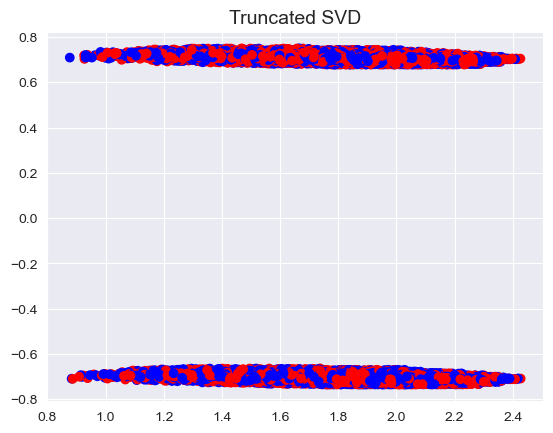

In [143]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.patches as mpatches

colors = ['red' if val == 'satisfied' else 'blue' for val in df_y2_train.values]
print(df_y2_train.shape)

fig, ax3 = plt.subplots()
ax3.scatter(X_reduced_svd[:,0], X_reduced_svd[:,1], c=colors)
ax3.set_title('Truncated SVD', fontsize=14)
ax3.grid(True)

## Model Evaluation

### Hyper-parameter tuning

#### for logistic regression

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
# For logistic regression, I try to tune hyperparameter c, and use the AUC-ROC to select the best hyper-parameters settings.

In [146]:
lr = LogisticRegression(random_state=42)
parameters = {'penalty':('l1', 'l2'), 
              'C': [0.1, *range(1, 11)],
              'solver': ['liblinear']} # 2*3*1 = 6 combinations

grid_cv = GridSearchCV(estimator = lr, param_grid = parameters, cv=5,scoring='roc_auc')

grid_cv.fit(df_X2_train, df_y2_train)

/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samp

GridSearchCV(cv=5, estimator=LogisticRegression(random_state=42),
             param_grid={'C': [0.1, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                         'penalty': ('l1', 'l2'), 'solver': ['liblinear']},
             scoring='roc_auc')

In [147]:
grid_cv.best_estimator_ 

LogisticRegression(C=0.1, penalty='l1', random_state=42, solver='liblinear')

In [148]:
grid_cv.cv_results_['mean_test_score']

array([0.49665614, 0.4961586 , 0.49627276, 0.49602897, 0.49616006,
       0.49602056, 0.4961188 , 0.49601784, 0.49608942, 0.49601571,
       0.49607152, 0.49601381, 0.49606273, 0.49601204, 0.49605316,
       0.49601155, 0.49604817, 0.49601111, 0.49604619, 0.49601065,
       0.49604313, 0.4960103 ])

##### refit the model with the best hyperparameters

In [157]:
lr_best = LogisticRegression(C=0.1, penalty='l1', random_state=42, solver='liblinear')
lr_best.fit(df_X2_train,df_y2_train)

/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression(C=0.1, penalty='l1', random_state=42, solver='liblinear')

In [ ]:
# model performance for the re-fit model

In [122]:
lr_best.score(df_X2_test,df_y2_test)

0.5048712785065042

In [123]:
prediction6 = lr_best.predict(df_X2_test)
print(classification_report(df_y2_test, prediction6, target_names=['satisfied', 'unsatisfied']))

              precision    recall  f1-score   support

   satisfied       0.50      0.84      0.63      9173
 unsatisfied       0.52      0.17      0.25      9200

    accuracy                           0.50     18373
   macro avg       0.51      0.51      0.44     18373
weighted avg       0.51      0.50      0.44     18373



We can see that the performance of the unsatified group is obviously lower than the satisfied group.
And the performance of the satisfied group has improved compared the previous model without tuning.

##### error analysis

In [159]:
confusion_matrix(df_y2_test, prediction6)

array([[7734, 1439],
       [7658, 1542]])

The model result has more false negatives than false positives, which indicates its lack of capability in predicting negative cases and distinguishing two groups.

##### pulling out the wrongly-predicted samples

In [173]:
# Combine df_X2_test and df_y2_test into one DataFrame
combined_df = pd.concat([df_X2_test, df_y2_test], axis=1)

In [174]:
# Convert prediction6 to a DataFrame with the same index as new_df
prediction_df = pd.DataFrame(prediction6, index=df_X2_test.index,columns=['Predicted'])
prediction_df.shape
prediction_df.head()

,Predicted
13813,satisfied
29766,satisfied
17692,satisfied
40069,satisfied
27674,satisfied


In [175]:
# Merge combined_df with prediction_df
merged_df = pd.concat([combined_df, prediction_df], axis=1)

# Display the merged DataFrame
merged_df.head

,income,purchase_amount,gender_Female,gender_Male,education_Bachelor,education_College,education_HighSchool,education_Masters,region_East,region_North,...,product_category_Food,product_category_Health,product_category_Home,promotion_usage_0,promotion_usage_1,purchase_frequency_frequent,purchase_frequency_occasional,purchase_frequency_rare,satisfaction_category,Predicted
13813,0.701022,0.573771,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,satisfied,satisfied
29766,0.638956,0.552392,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,satisfied,satisfied
17692,0.967067,0.975351,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,satisfied,satisfied
40069,0.939956,0.845465,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,unsatisfied,satisfied
27674,0.858800,0.750893,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,unsatisfied,satisfied


In [177]:
# Filter rows where Predicted is not equal to satisfaction_category
filtered_df = merged_df[merged_df['Predicted'] != merged_df['satisfaction_category']]

# Display the filtered DataFrame
filtered_df.head(50)

,income,purchase_amount,gender_Female,gender_Male,education_Bachelor,education_College,education_HighSchool,education_Masters,region_East,region_North,...,product_category_Food,product_category_Health,product_category_Home,promotion_usage_0,promotion_usage_1,purchase_frequency_frequent,purchase_frequency_occasional,purchase_frequency_rare,satisfaction_category,Predicted
40069,0.939956,0.845465,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,unsatisfied,satisfied
27674,0.858800,0.750893,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,unsatisfied,satisfied
56051,0.787511,0.638010,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,unsatisfied,satisfied
17779,0.272422,0.213290,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,unsatisfied,satisfied
34280,0.506133,0.355400,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,unsatisfied,satisfied
25983,0.777156,0.608833,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,unsatisfied,satisfied
55004,0.958244,0.836762,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,unsatisfied,satisfied
6650,0.205444,0.195131,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,unsatisfied,satisfied
3737,0.679356,0.538156,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,satisfied,unsatisfied
41408,0.269800,0.248151,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,unsatisfied,satisfied


After pulling the wrongly-predicted cases, we can further confirm that the model is inclinde to predict unsatisfied cases as satisfied but not satisfied cases as unsatisfied.
However, it's hard to find the pattern behind by observation(maybe there is no pattern).
One possible reason might be that the 5 is not a suitable thereshold for satisfation and unsatisfaction, therefore the target variable and its prediction does not align with the ground-truth data features.

#### for decision tree

In [ ]:
# We are trying to tune 'criterion','max_depth','min_samples_split'and 'min_samples_leaf'. 
# Also we use AUC_ROC to evaluate the best parameters.

In [151]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Instantiate the Decision Tree model
dt = DecisionTreeClassifier(random_state=42)

# Define the parameter grid for Decision Tree
parameters = {
    'criterion': ['gini', 'entropy'],   # Split criterion
    'max_depth': range(1, 11),  # Maximum depth of the tree
    'min_samples_split':range(1,6),    # Minimum number of samples required to split an internal node
    'min_samples_leaf': range(1,6),      # Minimum number of samples required to be at a leaf node
}

# Setup Grid Search with Cross-Validation
grid_cv = GridSearchCV(estimator=dt, param_grid=parameters, cv=5,scoring='roc_auc')

# Fit the model
grid_cv.fit(df_X2_train, df_y2_train)

/opt/anaconda3/lib/python3.11/site-packages/sklearn/model_selection/_validation.py:378: FitFailedWarning: 
500 fits failed out of a total of 2500.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
500 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.11/site-packages/sklearn/model_selection/_validation.py", line 686, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/opt/anaconda3/lib/python3.11/site-packages/sklearn/tree/_classes.py", line 889, in fit
    super().fit(
  File "/opt/anaconda3/lib/python3.11/site-packages/sklearn/tree/_classes.py", line 177, in fit
    self._validate_params()
  File "/opt/anaconda3/lib/python3.11/site-packages/sklearn/base.py

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': range(1, 11),
                         'min_samples_leaf': range(1, 6),
                         'min_samples_split': range(1, 6)},
             scoring='roc_auc')

In [160]:
grid_cv.best_estimator_

DecisionTreeClassifier(criterion='entropy', max_depth=8, min_samples_leaf=5,
                       random_state=42)

##### refit the model

In [161]:
dt_best=DecisionTreeClassifier(criterion='entropy', max_depth=8, min_samples_leaf=5,random_state=42)
dt_best.fit(df_X2_train, df_y2_train)

DecisionTreeClassifier(criterion='entropy', max_depth=8, min_samples_leaf=5,
                       random_state=42)

In [162]:
prediction7 = dt_best.predict(df_X2_test)
print(classification_report(df_y2_test, prediction7, target_names=['satisfied', 'unsatisfied']))

              precision    recall  f1-score   support

   satisfied       0.50      0.77      0.61      9173
 unsatisfied       0.51      0.24      0.33      9200

    accuracy                           0.50     18373
   macro avg       0.51      0.50      0.47     18373
weighted avg       0.51      0.50      0.47     18373



In [163]:
prediction7_numeric = [1 if label == 'satisfied' else 0 for label in prediction7]

# Convert df_y_test to numeric labels
df_y2_test_numeric = df_y2_test.replace({'satisfied': 1, 'unsatisfied': 0})

auc_roc = roc_auc_score(df_y2_test_numeric, prediction7_numeric)
print(auc_roc)

0.5036802063238521


We can see the overall performance is almost the same as previous model although the performance for satisfied group improved.

##### error analysis

In [179]:
confusion_matrix(df_y2_test, prediction7)

array([[7038, 2135],
       [6991, 2209]])

As logistic regression,the model result has more false negatives than false positives, which indicates its lack of capability in predicting negative cases and distinguishing two groups.

##### pulling out the wrongly-predicted samples

In [180]:
# Convert prediction7 to a DataFrame with the same index as new_df
prediction_df2 = pd.DataFrame(prediction7, index=df_X2_test.index,columns=['Predicted'])
prediction_df2.shape
prediction_df2.head()

,Predicted
13813,satisfied
29766,satisfied
17692,satisfied
40069,unsatisfied
27674,satisfied


In [183]:
# Merge combined_df with prediction_df
merged_df2 = pd.concat([combined_df, prediction_df2], axis=1)

# Display the merged DataFrame
merged_df2.head()

,income,purchase_amount,gender_Female,gender_Male,education_Bachelor,education_College,education_HighSchool,education_Masters,region_East,region_North,...,product_category_Food,product_category_Health,product_category_Home,promotion_usage_0,promotion_usage_1,purchase_frequency_frequent,purchase_frequency_occasional,purchase_frequency_rare,satisfaction_category,Predicted
13813,0.701022,0.573771,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,satisfied,satisfied
29766,0.638956,0.552392,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,satisfied,satisfied
17692,0.967067,0.975351,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,satisfied,satisfied
40069,0.939956,0.845465,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,unsatisfied,unsatisfied
27674,0.858800,0.750893,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,unsatisfied,satisfied


In [184]:
# Filter rows where Predicted is not equal to satisfaction_category
filtered_df2 = merged_df2[merged_df2['Predicted'] != merged_df2['satisfaction_category']]

# Display the filtered DataFrame
filtered_df2.head(50)

,income,purchase_amount,gender_Female,gender_Male,education_Bachelor,education_College,education_HighSchool,education_Masters,region_East,region_North,...,product_category_Food,product_category_Health,product_category_Home,promotion_usage_0,promotion_usage_1,purchase_frequency_frequent,purchase_frequency_occasional,purchase_frequency_rare,satisfaction_category,Predicted
27674,0.858800,0.750893,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,unsatisfied,satisfied
56051,0.787511,0.638010,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,unsatisfied,satisfied
273,0.179756,0.180190,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,satisfied,unsatisfied
34280,0.506133,0.355400,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,unsatisfied,satisfied
25983,0.777156,0.608833,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,unsatisfied,satisfied
8768,0.778844,0.671311,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,unsatisfied,satisfied
20629,0.944178,0.756829,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,satisfied,unsatisfied
41408,0.269800,0.248151,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,unsatisfied,satisfied
11212,0.508867,0.336285,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,unsatisfied,satisfied
43900,0.764956,0.576488,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,unsatisfied,satisfied


We have similar observations and conclusions as for logistic regression.

### Ensemble

#### Bagging

In [115]:
from sklearn.ensemble import BaggingClassifier

clf = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=2, random_state=42), n_estimators=10, random_state=0, 
                        max_samples=0.6, max_features=0.8, bootstrap=True)
clf.fit(df_X2_train, df_y2_train)

/opt/anaconda3/lib/python3.11/site-packages/sklearn/ensemble/_bagging.py:802: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=2,
                                                   random_state=42),
                  max_features=0.8, max_samples=0.6, random_state=0)

In [125]:
clf.score(df_X2_train, df_y2_train)

0.5100422216520096

In [126]:
prediction8 = clf.predict(df_X2_test)
print(classification_report(df_y2_test, prediction8, target_names=['satisfied', 'unsatisfied']))

              precision    recall  f1-score   support

   satisfied       0.50      0.98      0.66      9173
 unsatisfied       0.49      0.02      0.04      9200

    accuracy                           0.50     18373
   macro avg       0.49      0.50      0.35     18373
weighted avg       0.49      0.50      0.35     18373



In [128]:
prediction8_numeric = [1 if label == 'satisfied' else 0 for label in prediction8]
auc_roc = roc_auc_score(df_y2_test_numeric, prediction8_numeric)
print(auc_roc)

0.4994769562373506


The model performance of bagging is a little bit worse than the original model.
The pros of bagging is that it helps in reducing variance by averaging the predictions of multiple models trained on different subsets of the data, which often leads to more stable and reliable predictions. Also bagging models are less prone to overfitting compared to single models, especially in high-variance models like decision trees.
However, if the base learners are already biased towards a particular outcome, bagging might not significantly improve the model's performance. Our model might be of this kind of cases.

#### Boosting

In [134]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score
clf2 = AdaBoostClassifier(estimator=None, n_estimators=100, algorithm="SAMME")

In [141]:
scores = cross_val_score(clf2, df_X2_train, df_y2_train, cv=5)
scores.mean()

/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samp

0.5057267799636003

In [140]:
scores = cross_val_score(clf2, df_X2_train, df_y2_train, cv=5,scoring='roc_auc')
scores.mean()

/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/anaconda3/lib/python3.11/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samp

0.5020050441368102

Boosting methods like AdaBoost have strengh in better separation between classes and ultimately improve the AUC-ROC, since it could assign higher weights to misclassified instances in each iteration, which allows the algorithm to focus more on difficult-to-classify instances. 
However, boosting algorithms can be sensitive to noisy data and outliers as they tend to fit the data closely, which may lead to overfitting. Although its disadvantage is not that obvious in this case.